# JASC Code Classification: TF-IDF + Multinomial Naive Bayes
Classifies maintenance discrepancy text into JASC categories (first two digits of the JASC code).

## [1] Imports, paths and data loading

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

# File paths
input_file = (
    Path.home() / "Documents" / "AIE410_Project"
    / "Data_Preprocessed" / "Data_output.parquet"
)

output_file = (Path.home() / "Documents" / "AIE410_Project" / "Multinomial_Naive_Bayes_TFIDF")
output_file.mkdir(parents=True, exist_ok=True)

model_file = output_file / "jasc_multinomial_nb.joblib"
report_file = output_file / "jasc_nb_classification_report.csv"
predictions_file = output_file / "jasc_nb_test_predictions.csv"
confusion_matrix_file = output_file / "jasc_nb_confusion_matrix.png"

if not input_file.exists():
    raise FileNotFoundError(f"File not found: {input_file}")

df = pd.read_parquet(input_file)

required_columns = ["JASCCode", "Discrepancy"]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1765824, 76)


,OperatorControlNumber,DifficultyDate,SubmissionDate,OperatorDesignator,SubmitterDesignator,SubmitterTypeCode,ReceivingRegionCode,ReceivingDistrictOffice,SDRType,JASCCode,...,ButtLineFromSide,ButtlineTo,ButtlineToSide,WaterLineFrom,WaterLineTo,CrackLength,NumberOfCracks,CorrosionLevel,StructuralOther,Discrepancy
0,95UALD10001,01/03/1995,2000-03-26T17:11:31.060-05:00,UALA,<NA>,A,WP,29,A,3397,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,EEL LIGHT ON RT AISLE B ZONE INOPERATIVE. REP...
1,9500042202,01/03/1995,2000-03-26T17:11:31.060-05:00,NWAA,NWAA,A,GL,01,A,2741,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"DURING 5 DEGREE FLAP TAKEOFF AT 20 KNOTS, CENT..."
2,95UALD10002,01/03/1995,2000-03-26T17:11:31.060-05:00,UALA,<NA>,A,WP,29,A,3397,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,EEL STRIP LIGHT IN B ZONE LEFT AND RIGHT SIDE ...
3,95UAL757001,01/04/1995,2000-03-26T17:11:31.060-05:00,UALA,UALA,A,WP,29,A,2560,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"DURING OVERHAUL OF THE RIGHT OFF-WING SLIDE, T..."
4,CKSA94353,01/03/1995,2000-03-26T17:11:31.060-05:00,CKSA,CKSA,A,GL,23,A,7250,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,"KMCI - FLT 59901 - ON CLIMB-OUT, NR 3 ENGINE H..."


## [2] Environment setup for secure HTTPS and NLTK downloads

This code configures secure HTTPS certificate verification using the certifi certificate bundle, then imports NLTK tools for text preprocessing. It downloads the required language datasets (stopwords, wordnet, and omw-1.4) for tasks such as removing common words, stemming, and lemmatizing text.

In [2]:
import os
import ssl
import certifi

os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()
ssl._create_default_https_context = ssl.create_default_context
print("Certificate bundle:", certifi.where())

import re
import nltk
from functools import lru_cache
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer

# One-time downloads (safe to re-run)
for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

Certificate bundle: /Users/nileshsaumyadasa/Documents/AIE410_Project/.venv/lib/python3.14/site-packages/certifi/cacert.pem


## [3] Text cleaning and preprocessing

In [3]:
# Set the number of records to use; None means use all available data
SAMPLE_SIZE = 50000
# Set a fixed random seed so sampling and shuffling are reproducible
RANDOM_STATE = 42
# Choose how words are normalized: "lemma", "stem", or None
NORMALIZATION = "lemma"

# Load common English stop words, but keep negations because they are important
# for fault descriptions, such as "no leak", "not working", and "without damage"
STOP_WORDS = set(stopwords.words("english")) - {"no", "not", "nor", "without"}

# Select the word normalization method based on the NORMALIZATION setting
# Lemmatization converts words to their base forms; stemming removes word endings
# If None or an unrecognized option is provided, words remain unchanged
_norm = {
    "lemma": WordNetLemmatizer().lemmatize,
    "stem": PorterStemmer().stem
}.get(NORMALIZATION, lambda t: t)

# Cache previously normalized words to avoid processing repeated words again
_norm = lru_cache(maxsize=None)(_norm)

def preprocess_text(text):
    # Convert text to lowercase and replace punctuation and special characters
    # with spaces, then split the text into individual words
    tokens = re.sub(r"[\W_]+", " ", str(text).lower()).split()

    # Remove stop words, normalize the remaining words, and join them into
    # a single cleaned text string
    return " ".join(_norm(t) for t in tokens if t not in STOP_WORDS)


# Select the discrepancy descriptions and JASC codes for processing
data = df[["Discrepancy", "JASCCode"]].copy()

# Remove leading and trailing whitespace from discrepancy descriptions
data["Discrepancy"] = data["Discrepancy"].astype("string").str.strip()

# Convert JASC codes to numbers; invalid values become missing values
data["JASCCode"] = pd.to_numeric(data["JASCCode"], errors="coerce")

# Remove rows with missing values
data = data.dropna()

# Keep only non-empty descriptions and valid JASC codes that are
# non-negative whole numbers
data = data[
    (data["Discrepancy"] != "")
    & (data["JASCCode"] >= 0)
    & (data["JASCCode"] % 1 == 0)
]

# Create a broader JASC category using the first two digits of each code
# Example: JASC code 3210 becomes category "32"
data["JASC_Category"] = (
    data["JASCCode"].astype("int64").astype(str).str[:2]
)

# If a sample size is specified and the dataset is larger than that size,
# randomly select the specified number of records to reduce processing time
if SAMPLE_SIZE and len(data) > SAMPLE_SIZE:
    data = data.sample(SAMPLE_SIZE, random_state=RANDOM_STATE)

# Apply text preprocessing to each discrepancy description and save the
# cleaned result in a new column called Clean_Text
data["Clean_Text"] = data["Discrepancy"].map(preprocess_text)

# Remove descriptions that become empty after preprocessing
# Remove duplicate combinations of cleaned text and JASC category
# Shuffle the records and reset the row index
data = (
    data[data["Clean_Text"] != ""]
    .drop_duplicates(["Clean_Text", "JASC_Category"])
    .sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

# X contains the cleaned descriptions used as model inputs
# y contains the JASC categories the model will learn to predict
X, y = data["Clean_Text"], data["JASC_Category"]

# Print the total number of records and unique JASC categories
print(f"Samples: {len(data):,} | Categories: {y.nunique():,}")

# Display the number of records in each JASC category
display(
    y.value_counts()
    .sort_index()
    .rename("SampleCount")
    .to_frame()
)

# Display a preview of the original descriptions, cleaned text,
# and corresponding JASC categories
display(data[["Discrepancy", "Clean_Text", "JASC_Category"]].head())

Samples: 49,763 | Categories: 50


,SampleCount
JASC_Category,
11,40
12,1
14,28
18,1
21,1382
22,231
23,205
24,597
25,2182


,Discrepancy,Clean_Text,JASC_Category
0,"PIT - Q5, FLOOR SUPPORT, .1250 INCH BY .1250 I...",pit q5 floor support 1250 inch 1250 inch area ...,53
1,AIRCRAFT WAS IN BASE MAINTENANCE: DURING INSPE...,aircraft base maintenance inspection found rig...,57
2,STGR 18R IN MAIN E&E BAY CORRODED BETWEEN FS28...,stgr 18r main e e bay corroded fs280 fs295 r r...,53
3,COCKPIT CAPTAIN'S LEFT AND RIGHT LAP BEL...,cockpit captain left right lap belt damaged re...,25
4,CORROSION ON THE FUSELAGE SKIN AT STRINGERS 38...,corrosion fuselage skin stringer 38l 39l fusel...,53


## [4] Split into training and testing datasets

In [4]:
# Count how many samples belong to each JASC category
class_counts = y.value_counts()

# Count the total number of unique JASC categories
n_classes = y.nunique()

# Ensure there are enough samples to create training and testing datasets
if len(data) < 4:
    raise ValueError("Select at least 4 samples for a train/test split.")

# Ensure there are at least two categories for the model to classify
if n_classes < 2:
    raise ValueError("At least 2 distinct JASC categories are required.")

# Calculate the number of samples for testing (20%), rounding up
n_test = int(np.ceil(0.20 * len(data)))

# Assign the remaining 80% of samples to training
n_train = len(data) - n_test

# Check whether stratified splitting is possible.
# Each category must have at least 2 samples, and both datasets must
# have enough space to include every category.
can_stratify = (
    class_counts.min() >= 2
    and n_test >= n_classes
    and n_train >= n_classes
)

# Split the data into training and testing sets.
# Training data is used to teach the model, while testing data evaluates
# how well the model predicts categories on unseen descriptions.
# Stratification preserves category proportions when the data allows it.
# RANDOM_STATE ensures the split is reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y if can_stratify else None,
)

# Display the number of samples assigned to the training dataset
print(f"Training samples: {len(X_train):,}")

# Display the number of samples assigned to the testing dataset
print(f"Testing samples:  {len(X_test):,}")

# Display how many unique JASC categories appear in the training dataset
print(f"Training classes: {y_train.nunique():,}")

# Show whether stratified splitting was used
print(f"Stratified split: {can_stratify}")

Training samples: 39,810
Testing samples:  9,953
Training classes: 50
Stratified split: False


## [5] Create and train the TF-IDF + Multinomial Naive Bayes pipeline

In [5]:
# Create a machine learning pipeline that combines text processing
# with a classifier to predict JASC categories from discrepancy descriptions
model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,           # Convert all text to lowercase
            strip_accents="unicode",  # Remove accent marks from characters
            ngram_range=(1, 2),       # Use single words and two-word combinations
            max_features=50000,       # Keep at most 50,000 text features
            sublinear_tf=True,        # Reduce the influence of frequently repeated words
            min_df=2,                 # Ignore words or phrases appearing in fewer than 2 documents
            dtype=np.float64,         # Store TF-IDF values as 64-bit floating-point numbers
        ),
    ),
    (
        "classifier",
        MultinomialNB(
            alpha=0.01,                # Laplace/Lidstone smoothing.. smaller values trust the training counts more
            fit_prior=True,           # Learn class priors from the training data (False = uniform priors,
                                      # which can help rare categories; MultinomialNB has no class_weight option)
        ),
    ),
])

# Train the pipeline using the training descriptions and their JASC categories.
# TF-IDF converts text into numerical features, and Multinomial Naive Bayes learns
# per-category word probabilities to classify those features into the appropriate JASC categories.
print("Training TF-IDF + Multinomial Naive Bayes...")
model.fit(X_train, y_train)

# Confirm that training has finished
print("Training completed.")

# Display the number of text features created by the TF-IDF vectorizer
print("TF-IDF features:", len(model.named_steps["tfidf"].vocabulary_))

# Display the number of distinct JASC categories learned by the classifier
print("Classes learned:", len(model.named_steps["classifier"].classes_))

Training TF-IDF + Multinomial Naive Bayes...
Training completed.
TF-IDF features: 50000
Classes learned: 50


## [6] Evaluate model performance

In [6]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
weighted_f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"Accuracy:    {accuracy:.4f}")
print(f"Macro F1:    {macro_f1:.4f}")
print(f"Weighted F1: {weighted_f1:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy:    0.8693
Macro F1:    0.6078
Weighted F1: 0.8632

Classification report:
              precision    recall  f1-score   support

          11       1.00      0.22      0.36         9
          14       0.00      0.00      0.00         9
          21       0.70      0.94      0.80       246
          22       0.86      0.69      0.77        45
          23       0.90      0.63      0.74        41
          24       0.71      0.80      0.75       108
          25       0.84      0.78      0.81       444
          26       0.86      0.91      0.88       118
          27       0.78      0.79      0.79       261
          28       0.82      0.82      0.82       102
          29       0.77      0.80      0.78        84
          30       0.80      0.56      0.66        70
          31       0.56      0.23      0.32        44
          32       0.80      0.93      0.86       368
          33       0.96      0.97      0.97      1458
          34       0.82      0.81      0.81       1

## [7] Save model, report, predictions and confusion matrix

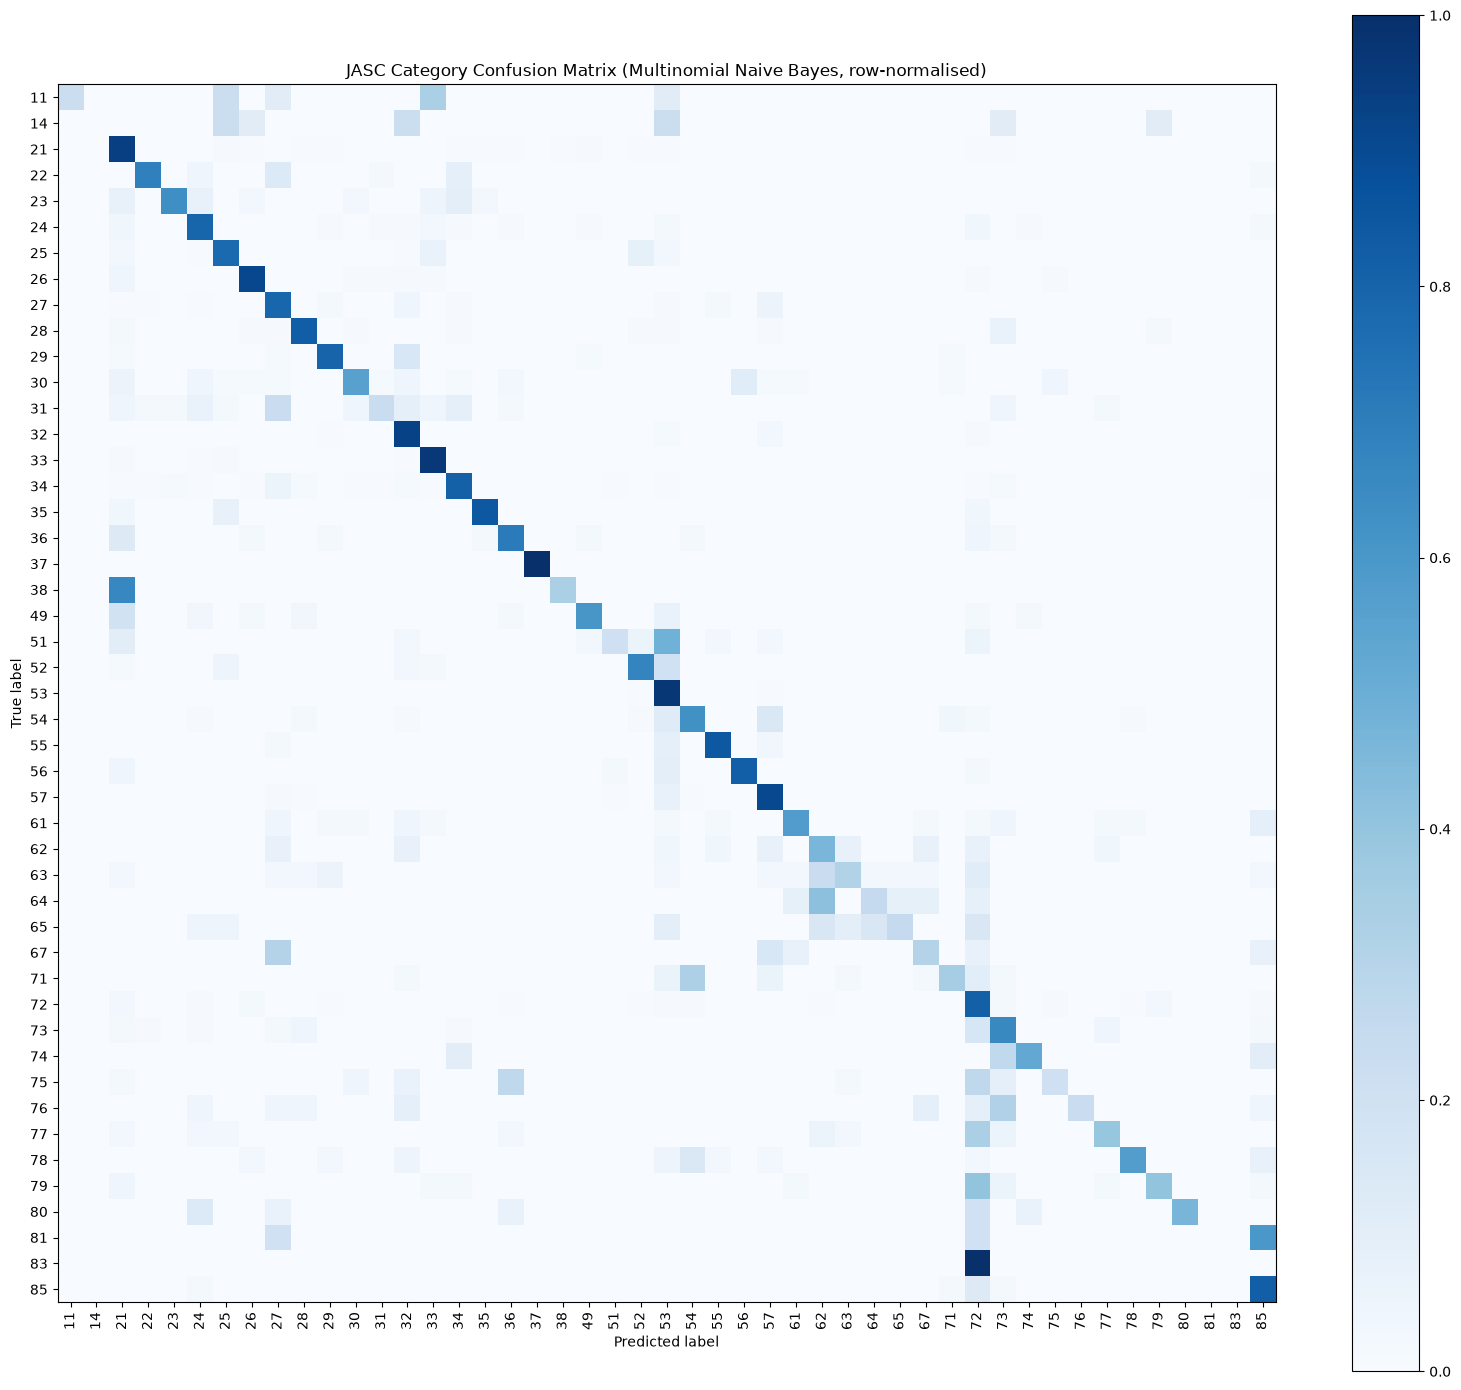

Saved:
 - /Users/nileshsaumyadasa/Documents/AIE410_Project/Multinomial_Naive_Bayes_TFIDF/jasc_multinomial_nb.joblib
 - /Users/nileshsaumyadasa/Documents/AIE410_Project/Multinomial_Naive_Bayes_TFIDF/jasc_nb_classification_report.csv
 - /Users/nileshsaumyadasa/Documents/AIE410_Project/Multinomial_Naive_Bayes_TFIDF/jasc_nb_test_predictions.csv
 - /Users/nileshsaumyadasa/Documents/AIE410_Project/Multinomial_Naive_Bayes_TFIDF/jasc_nb_confusion_matrix.png


In [7]:
# Classification report
report_df = pd.DataFrame(
    classification_report(y_test, y_pred, zero_division=0, output_dict=True)
).T
report_df.to_csv(report_file)

# Test predictions with predicted class probability (confidence)
probs = model.predict_proba(X_test)
top_prob = probs.max(axis=1)

pred_df = pd.DataFrame({
    "Clean_Text": X_test.values,
    "True_JASC_Category": y_test.values,
    "Predicted_JASC_Category": y_pred,
    "Confidence": top_prob,
})
pred_df.to_csv(predictions_file, index=False)

# Confusion matrix (row-normalised so large classes don't dominate)
fig, ax = plt.subplots(figsize=(16, 14))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    normalize="true",
    include_values=False,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
)
ax.set_title("JASC Category Confusion Matrix (Multinomial Naive Bayes, row-normalised)")
plt.tight_layout()
fig.savefig(confusion_matrix_file, dpi=200)
plt.show()

# Model
joblib.dump(model, model_file)

print("Saved:")
for p in [model_file, report_file, predictions_file, confusion_matrix_file]:
    print(" -", p)

## [8] Predict on new text

In [8]:
example_text = ["Inspected engine oil filter area and identified oil leakage at the filter seal. Replaced seal, serviced engine oil to the specified level, and performed an engine run-up. No further leakage observed"]

# Apply the same preprocessing used for training
example_clean = [preprocess_text(t) for t in example_text]

predicted = model.predict(example_clean)
probs = model.predict_proba(example_clean)[0]

print("Predicted JASC category:", predicted[0])

# Top 5 candidate categories by predicted probability
top5 = np.argsort(probs)[::-1][:5]
classes = model.named_steps["classifier"].classes_
for i in top5:
    print(f"  {classes[i]}  probability={probs[i]:.3f}")

Predicted JASC category: 72
  72  probability=0.860
  79  probability=0.137
  73  probability=0.001
  29  probability=0.001
  21  probability=0.000
